In [1]:
import matplotlib.pyplot as plt
import numpy as np
import stim

import os 

while 'honeycomb.py' not in os.listdir():
    os.chdir("..")

from honeycomb import CSSHoneycomb
from operations import Detector
from testing.codespace_distance import check_noiseless, effective_distance


from sims import run_experiment, build_circuit, check_circuit,estimate_logical_error_rate
from collections import defaultdict
import json

from phenom_honeycomb import build_phenomenological_circuit, PhenomenologicalHoneycomb, PhenomenologicalNoise 

In [2]:
noise = PhenomenologicalNoise(p_data=1e-3, p_meas=1e-3)

circuit = build_phenomenological_circuit(
    ["bZ", "rX", "gZ", "bX"],   # your measurement cycle
    ncols=5, nrows=4,
    noise=noise,
    config_filepath="config/5x4.json",
    observables=True
)

print(circuit)   # raw stim text, check the MPP lines and noise placement

QUBIT_COORDS(0, 0) 1
QUBIT_COORDS(1, 0) 2
QUBIT_COORDS(2, 0) 3
QUBIT_COORDS(3, 0) 4
QUBIT_COORDS(4, 0) 5
QUBIT_COORDS(0, 1) 6
QUBIT_COORDS(1, 1) 7
QUBIT_COORDS(2, 1) 8
QUBIT_COORDS(3, 1) 9
QUBIT_COORDS(4, 1) 10
QUBIT_COORDS(5, 1) 11
QUBIT_COORDS(1, 2) 12
QUBIT_COORDS(2, 2) 13
QUBIT_COORDS(3, 2) 14
QUBIT_COORDS(4, 2) 15
QUBIT_COORDS(5, 2) 16
QUBIT_COORDS(6, 2) 17
QUBIT_COORDS(2, 3) 18
QUBIT_COORDS(3, 3) 19
QUBIT_COORDS(4, 3) 20
QUBIT_COORDS(5, 3) 21
QUBIT_COORDS(6, 3) 22
QUBIT_COORDS(2, -1) 0
R 1 2 3 4 8 13 14 15 18 19 20 21 22 0
RX 5 6 7 9 10 11 12 16 17
X_ERROR(0.001) 1 2 3 4 13 14 15 18 19 20 21 22
Z_ERROR(0.001) 5 6 7 9 10 11 12 16 17
DEPOLARIZE1(0.001) 8
TICK
H 0
CX 0 8
TICK
DEPOLARIZE1(0.001) 1 2 3 4 5 6 7 8 9 10 11 12 13 14 15 16 17 18 19 20 21 22
MPP(0.001) Z3*Z4 Z5*Z10 Z7*Z12 Z8*Z9 Z13*Z14 Z15*Z20 Z16*Z17 Z18*Z19 Z21*Z22 Z2 Z1
DETECTOR(1.75, 0, 2) rec[-11] rec[-2]
DETECTOR(2.5, 0, 2) rec[-11]
DETECTOR(2.5, 2, 2) rec[-7]
DETECTOR(4, 2.5, 2) rec[-6]
DETECTOR(2.5, 3, 2) rec[-4]
DE

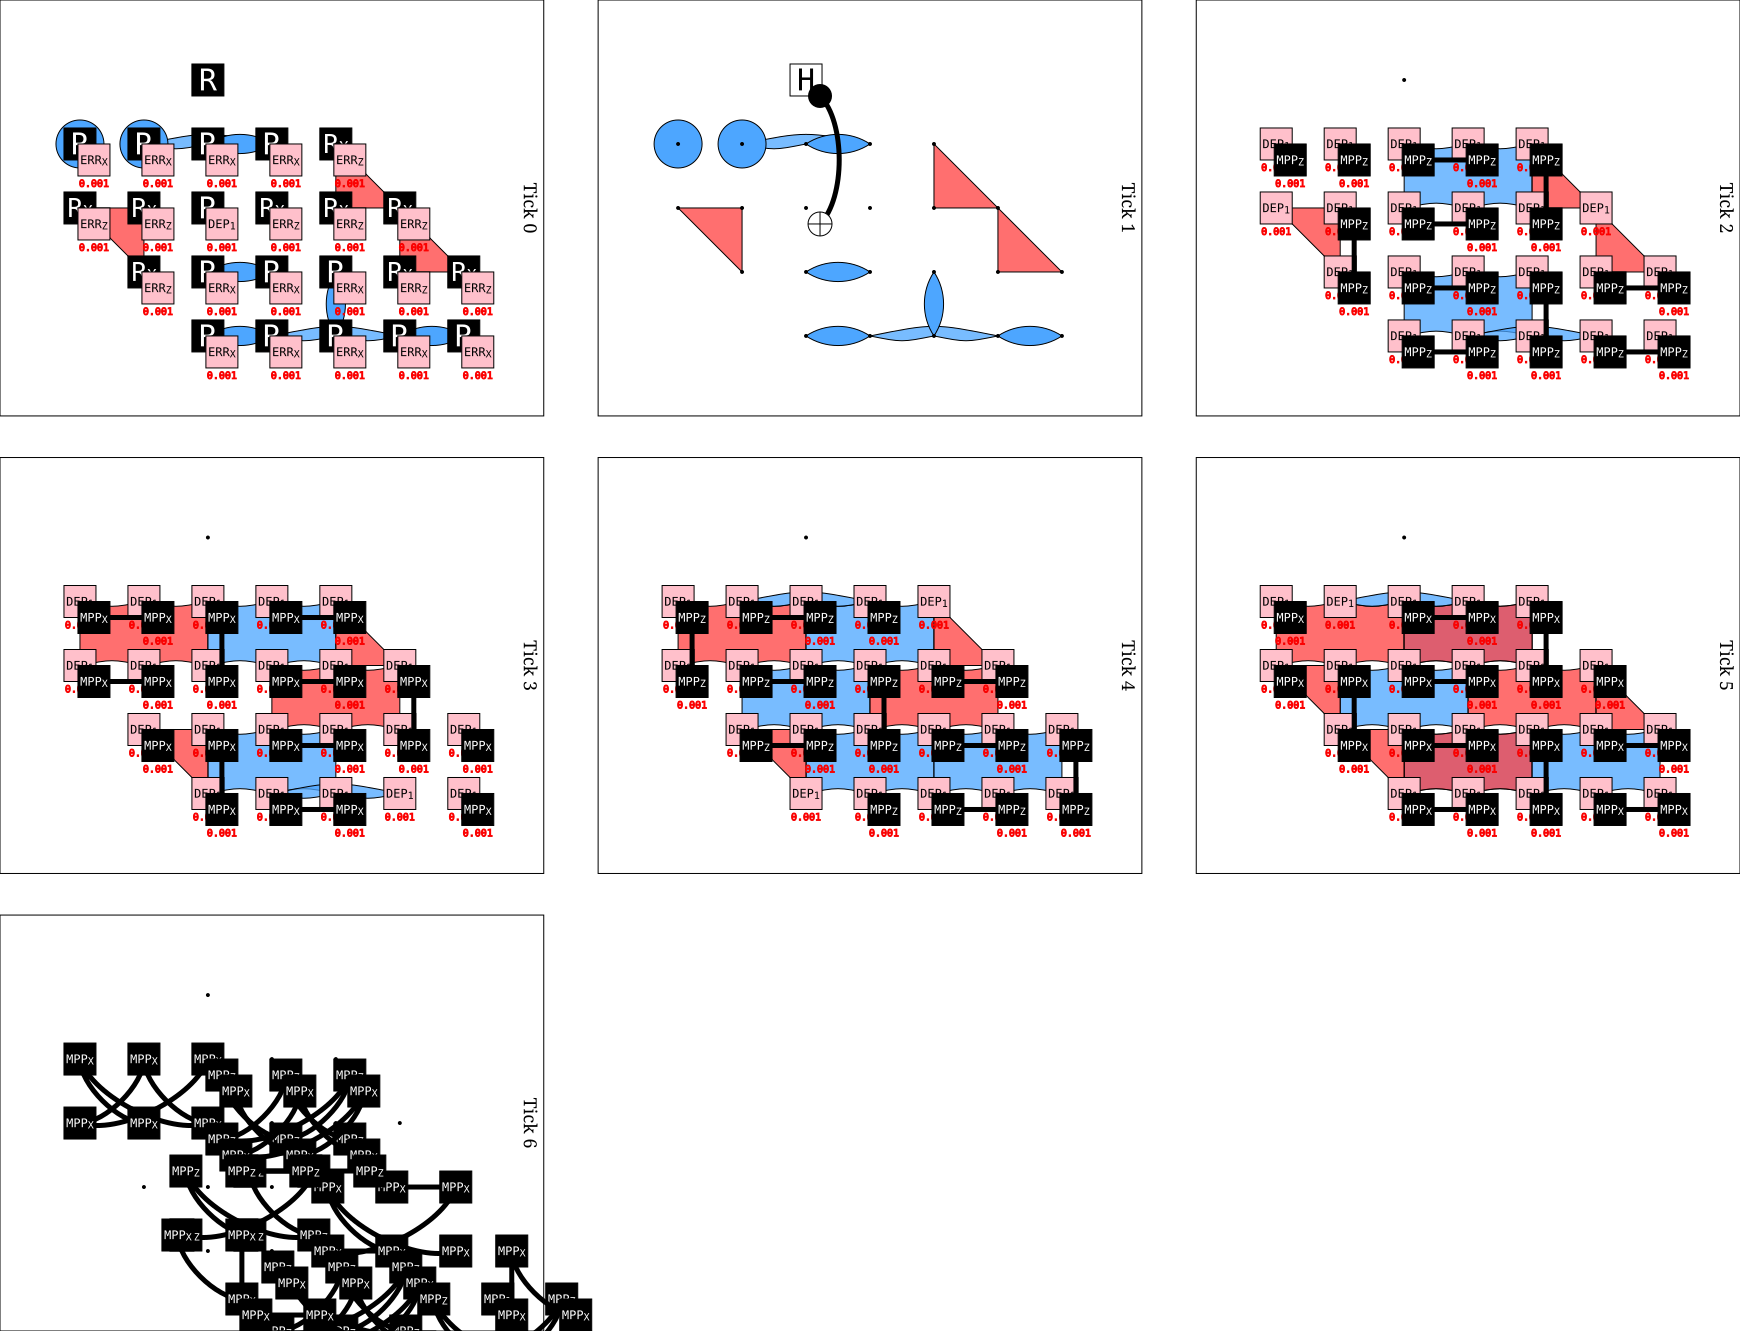

In [3]:
circuit.diagram("detslice-with-ops-svg")

In [4]:
print(len(circuit.shortest_graphlike_error()))

1


In [5]:

noise = PhenomenologicalNoise(p_data=1e-3, p_meas=0.0)
circuit = PhenomenologicalHoneycomb.build_injection_circuit(
    noise, ncols=5, nrows=3, config_filepath="config/5x3.json",
    ideal_cycle=("bZ", "rX", "gZ", "bX"),
    noisy_cycle=("rZ", "gX", "bZ", "rX", "gZ", "bX")*2
)
check_noiseless(circuit)
effective_distance(circuit)

effective distance: 2
[stim.DemTargetWithCoords(dem_target=stim.DemTarget('D14'), coords=[2.25, 0, 8])] <- CircuitErrorLocation {
    flipped_pauli_product: X4[coords 3,0]
    Circuit location stack trace:
        (after 7 TICKs)
        at instruction #46 (DEPOLARIZE1) in the circuit
        at target #4 of the instruction
        resolving to DEPOLARIZE1(0.001) 4[coords 3,0]
}
[stim.DemTargetWithCoords(dem_target=stim.DemTarget('D14'), coords=[2.25, 0, 8]), stim.DemTargetWithCoords(dem_target=stim.DemTarget('L0'), coords=[])] <- CircuitErrorLocation {
    flipped_pauli_product: X2[coords 1,0]
    Circuit location stack trace:
        (after 6 TICKs)
        at instruction #41 (DEPOLARIZE1) in the circuit
        at target #2 of the instruction
        resolving to DEPOLARIZE1(0.001) 2[coords 1,0]
}


2

In [6]:
for i, inst in enumerate(circuit):
    if 38 <= i <= 46:
        print(i, inst)

38 DETECTOR(4.5, 0.75, 5) rec[-8] rec[-3]
39 TICK
40 DEPOLARIZE1(0.001) 1 2 3 4 5 6 7 8 9 10 11 12 13 14 15 16
41 MPP Z1*Z2 Z3*Z8 Z4*Z5 Z6*Z7 Z9*Z10 Z11*Z16 Z14*Z15 Z13
42 DETECTOR(3, 0.5, 6) rec[-42] rec[-41] rec[-39] rec[-7] rec[-6] rec[-4]
43 DETECTOR(3.25, 2, 6) rec[-38] rec[-36] rec[-2] rec[-1]
44 TICK
45 DEPOLARIZE1(0.001) 1 2 3 4 5 6 7 8 9 10 11 12 13 14 15 16
46 MPP X1*X6 X2*X3 X7*X8 X9*X14 X10*X11 X12*X13 X15*X16 X5


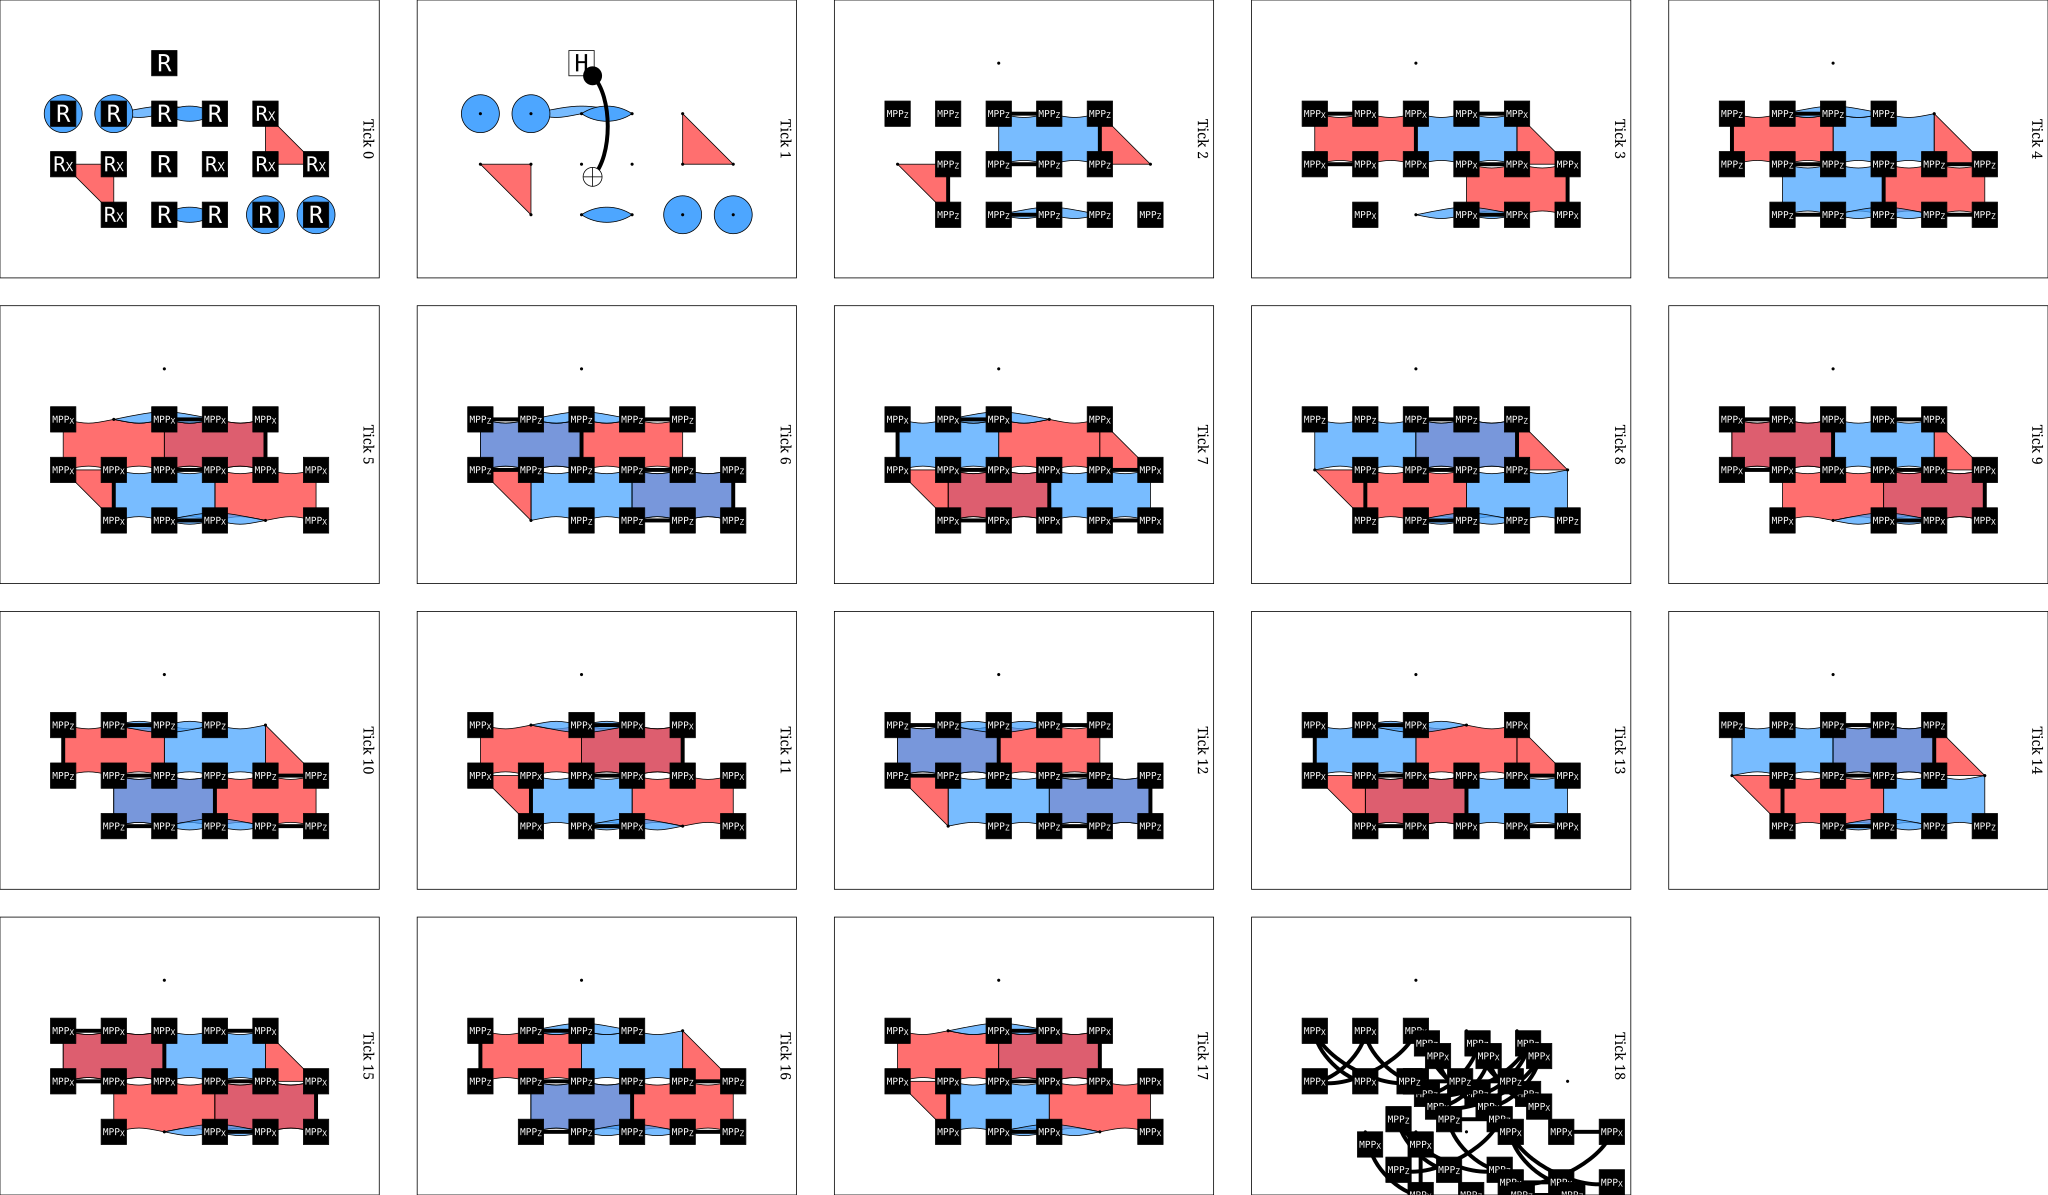

In [10]:
# circuit.without_noise().diagram("detslice-svg", tick=range(4, 8), filter_coords=["D14", "L0"])
# circuit.without_noise().diagram("detslice-svg", tick=range(4, 8))
circuit.without_noise().diagram("detslice-with-ops-svg")

In [8]:
# what's in D14, and which qubits does it touch?
print(circuit.get_detector_coordinates([14]))
for inst in circuit:
    if inst.name == "DETECTOR" and inst.gate_args_copy()[:2] == [2.25, 0]:
        print(inst)

# neighbours of the faulty qubits
print(circuit.get_final_qubit_coordinates())   # find which plaquettes contain 2 and 4

{14: [2.25, 0.0, 8.0]}
DETECTOR(2.25, 0, 8) rec[-41] rec[-35] rec[-9] rec[-4]
DETECTOR(2.25, 0, 14) rec[-41] rec[-35] rec[-9] rec[-4]
DETECTOR(2.25, 0, 18) rec[-24] rec[-18] rec[-3]
{0: [2.0, -1.0], 1: [0.0, 0.0], 2: [1.0, 0.0], 3: [2.0, 0.0], 4: [3.0, 0.0], 5: [4.0, 0.0], 6: [0.0, 1.0], 7: [1.0, 1.0], 8: [2.0, 1.0], 9: [3.0, 1.0], 10: [4.0, 1.0], 11: [5.0, 1.0], 12: [1.0, 2.0], 13: [2.0, 2.0], 14: [3.0, 2.0], 15: [4.0, 2.0], 16: [5.0, 2.0]}


In [11]:
import numpy as np

def detector_rank(circuit):
    n, rows = 0, []
    for inst in circuit.flattened():
        if inst.name == "DETECTOR":
            rows.append({n + t.value for t in inst.targets_copy()})  # rec[-k] -> value is -k
        elif inst.name in ("M", "MX", "MY", "MPP", "MR", "MRX"):
            n += inst.num_measurements
    return rows, n

def gf2_rank(sets, n):
    m = np.zeros((len(sets), n), dtype=np.uint8)
    for i, s in enumerate(sets):
        for j in s:
            m[i, j] = 1
    rank = 0
    for c in range(n):
        piv = next((r for r in range(rank, len(m)) if m[r, c]), None)
        if piv is None:
            continue
        m[[rank, piv]] = m[[piv, rank]]
        for r in range(len(m)):
            if r != rank and m[r, c]:
                m[r] ^= m[rank]
        rank += 1
    return rank

clean = circuit.without_noise()
rows, n = detector_rank(clean)
mine = gf2_rank(rows, n)

flows = [f for f in clean.flow_generators()
         if len(f.input_copy()) == 0 or f.input_copy().weight == 0
         if f.output_copy().weight == 0]
full = gf2_rank([set(f.measurements_copy()) for f in flows], n)
print("my detectors:", mine, " all deterministic:", full)

my detectors: 40  all deterministic: 40
